# Warp inference test (upscale / downscale)

In [1]:
import numpy as np

import os
import sys
# make npe_mx_emu importable whether jupyter runs from the repo root or from EL_nb/
_here = os.getcwd()
_cands = [_here, os.path.dirname(_here)]  # EL_nb/ -> parent
for _c in _cands:
    if os.path.isdir(os.path.join(_c, 'npe_mx_emu')) and _c not in sys.path:
        sys.path.insert(0, _c)
        break

import numpy as np
import torch

torch.manual_seed(0)


## Warp inference


## Test helpers

Image generation, scale-grid creation, quantized HW grid and the float
`grid_sample` reference (mirrors `torch.nn.functional.grid_sample`).

In [2]:
def generate_bg(width, height) -> torch.Tensor:
    grad = torch.round(torch.linspace(0, 1, height, dtype=torch.float64) * (255 - 135) + 135)
    val = torch.vstack([grad, torch.ones_like(grad) * 206, torch.ones_like(grad) * 235]).to(torch.uint8)
    sky = val.T.unsqueeze(1).expand(-1, width, -1).contiguous()   # (height, width, 3)
    return sky


def generate_green_ball(width, height, img) -> torch.Tensor:
    center = (width // 2, height // 2)  # Center of the image
    radius = width // 4
    xs, ys = torch.meshgrid((torch.arange(width) - center[0]).double(),
                            (torch.arange(height) - center[1]).double(), indexing='xy')
    dist = torch.hypot(xs, ys)
    mask = dist < radius
    grad = 1 - dist / radius
    ball = torch.zeros_like(img)
    ball[..., 1] = torch.clamp(grad * 255, 0, 255).to(img.dtype)
    img = torch.where(mask.unsqueeze(-1), ball, img)
    return img


def generate_image(height, width) -> torch.Tensor:

    # Create image
    image = generate_bg(width, height)

    # Add green ball with gradient and texture
    image = generate_green_ball(width, height, image)
    return image


def grid_sample(tensor: torch.Tensor, grid: torch.Tensor) -> torch.Tensor:
    """Given an input and a flow-field grid, computes the output using input
    values and pixel locations from grid.

    Args:
        tensor: (N, C, H_in, W_in) tensor
        grid: (N, H_out, W_out, 2) tensor in the range of [-1, 1]

    Returns:
        (N, C, H_out, W_out) tensor

    See `torch.nn.functional.grid_sample`.
    """
    b, c, h, w = tensor.shape
    b_, h_out, w_out, w_ = grid.shape
    assert b == b_ and w_ == 2
    out = []
    for (t, g) in zip(tensor, grid):
        x_ = 0.5 * (w - 1) * (g[..., 0].reshape(-1) + 1)
        y_ = 0.5 * (h - 1) * (g[..., 1].reshape(-1) + 1)
        ix = torch.floor(x_).clamp(0, w - 2).long()
        iy = torch.floor(y_).clamp(0, h - 2).long()
        dx = x_ - ix
        dy = y_ - iy
        out.append((1 - dx) * (1 - dy) * t[..., iy, ix]
                   + dx * (1 - dy) * t[..., iy, ix + 1]
                   + (1 - dx) * dy * t[..., iy + 1, ix]
                   + dx * dy * t[..., iy + 1, ix + 1])
    return torch.cat(out, dim=0).reshape(b, c, h_out, w_out)


def create_scale_grid(reference_height, reference_width, grid_height, grid_width):
    grid = torch.dstack(torch.meshgrid(torch.linspace(0, reference_width - 1, grid_width, dtype=torch.float64),
                                       torch.linspace(0, reference_height - 1, grid_height, dtype=torch.float64),
                                       indexing='xy'))
    grid = grid[None, ...]
    return grid


In [3]:
def gen_warp_weights(x_frac, y_frac, frac_bits):
    w00 = (2 ** frac_bits[0][0] - x_frac) * (2 ** frac_bits[0][1] - y_frac)
    w10 = (2 ** frac_bits[0][0] - x_frac) * (y_frac)
    w01 = (x_frac) * (2 ** frac_bits[0][1] - y_frac)
    w11 = (x_frac) * (y_frac)

    return w00, w01, w10, w11


def get_ref_frame(src, x_offset, y_offset):
    # this is a relative grid and to be able to handle the last element in the line it copied
    print(src.shape[2:])
    src_height, src_width = src.shape[2:]

    xs0 = torch.clamp(torch.floor(x_offset), 0, src_width - 2).long()
    ys0 = torch.clamp(torch.floor(y_offset), 0, src_height - 2).long()
    
    ref00 = src[..., ys0, xs0]
    ref01 = src[..., ys0, xs0 + 1]
    ref10 = src[..., ys0 + 1, xs0]
    ref11 = src[..., ys0 + 1, xs0 + 1]

    return ref00, ref01, ref10, ref11


# new warp: implement the TRC here
def trc(quantized_grid, src, frac_bits):
    x_offset, x_frac = split_msb_lsb(quantized_grid[0, 0, ...].to(dtype=torch.int16), frac_bits[0][0])
    y_offset, y_frac = split_msb_lsb(quantized_grid[0, 1, ...].to(dtype=torch.int16), frac_bits[0][1])
    # interpulate_weights = torch.stack(gen_warp_weights(x_frac, y_frac))
    # frame_coords = torch.stack(get_ref_frame(src, ys0, xs0))

    tru_a = gen_warp_weights(x_frac, y_frac, frac_bits)
    tru_w = get_ref_frame(src, x_offset, y_offset)

    return tru_a, tru_w

def to_calculate_in_bcu(tru_a, tru_w):
    w00, w01, w10, w11= tru_a
    ref00, ref01, ref10, ref11 = tru_w
    out00 = ref00 * w00[None, None, ...]
    out01 = ref01 * w01[None, None, ...]
    out10 = ref10 * w10[None, None, ...]
    out11 = ref11 * w11[None, None, ...]

    out = out00 + out01 + out10 + out11
    return out 


def grid_quantization(
    grid,
    grid_bit_width: int,

):

    delta_grid = grid
    max_motion = torch.ceil(torch.abs(delta_grid.reshape((-1, 2))).max(dim=0).values)
    frac_bits = grid_bit_width - torch.floor(torch.log2(max_motion)) - 2
    # TODO add assertions to avoid 0 frac bits and more than 8 frac bits
    delta_grid = torch.round(delta_grid * frac_bits.exp2()).to(torch.int16)
    delta_grid = delta_grid.permute(2, 0, 1)[None, ...]
    
    return delta_grid, max_motion, frac_bits.reshape(1, 2, 1, 1)


def split_msb_lsb(q: torch.Tensor, frac_bits):
    """Extract the msb/lsb split of a fixed-point integer grid.

        idx  = q >> frac_bits          # msb: reference index (floor, works for negatives)
        frac = q & (2**frac_bits - 1)  # lsb: fraction, always in [0, 2**frac_bits)

    Guarantees  q == idx * 2**frac_bits + frac  also for signed q
    (arithmetic shift + two's-complement mask).

    frac_bits can be a scalar or broadcastable to q (e.g. per-axis [1, 2, 1, 1]).
    Returns (idx, frac) as long tensors.
    """
    if not q.dtype in (torch.int16, torch.int32, torch.int64):
        raise TypeError(f"expected an integer grid, got {q.dtype}")
    fr = torch.as_tensor(frac_bits).long()
    idx = q.long() >> fr
    frac = q.long() & ((torch.ones_like(fr) << fr) - 1)
    return idx, frac


def dequant_warp_res(out, frac_bits):
    return out / 2. ** frac_bits.sum()

## Run one warp test

Compares three results:
- **expected** — float grid through `grid_sample`
- **q_res** — quantized (16-bit HW) grid through `npe hardware emulator`
- **result** — quantized grid through the HW model `infer_warp`

Assert: `q_expected` and HW `result` match with `atol=1`.

## Downscale: 320x240 -> 106x80

In [4]:
reference_height, reference_width, grid_height, grid_width = 240, 320, 80, 106
grid_bits = 16
x_downscale = generate_image(reference_height, reference_width).permute(2, 0, 1).unsqueeze(0)
grid_downscale = create_scale_grid(reference_height, reference_width, grid_height, grid_width)


In [5]:
# get expected output
new_h, new_w = grid_downscale.shape[-3:-1]
orig_h, orig_w = x_downscale.shape[-2:]

grid_norm_scale = 2 / torch.tensor([orig_w - 1, orig_h - 1], dtype=torch.float64).reshape((1, 1, 1, -1))
grid_normed = grid_norm_scale * grid_downscale - 1
expected_downscale = grid_sample(x_downscale, grid_normed)

In [6]:
quantized_grid, max_motion, frac_bits = grid_quantization(
    grid_downscale[0],
    grid_bits
)

src = x_downscale.clone()
tru_a, tru_w = trc(quantized_grid, src, frac_bits)
out2 = to_calculate_in_bcu(tru_a, tru_w)
q_res_downscale = dequant_warp_res(out2, frac_bits)

torch.Size([240, 320])


In [19]:
from npe_mx_emu.layers import CalibratedMXWarp
from npe_mx_emu import LayerMXQParams, CalibratedMXConv2d, MXObserver

obs_x1 = MXObserver(mode="input"); obs_x1.update(x_downscale)
obs_grid1 = MXObserver(mode="input", mx_type='mx-e4bm16'); obs_grid1.update(grid_downscale)

qparams = LayerMXQParams(obs_x1, obs_grid1, is_input_layer=True)
npe_channels = x_downscale.shape[-3]
npe_warp = CalibratedMXWarp(
    channels=npe_channels,
    qparams=qparams
)

npe_warp.calibrate()
npe_warp_emu_downscale = npe_warp(x_downscale, grid_downscale)


In [20]:
# run inference
name = "downscale"
print(f'[{name}] mse q_expected vs hw result: {((expected_downscale - q_res_downscale) ** 2).mean():.3f}')
print(f'[{name}] mse q_expected vs hw result: {((expected_downscale - npe_warp_emu_downscale) ** 2).mean():.3f}')


[downscale] mse q_expected vs hw result: 0.007
[downscale] mse q_expected vs hw result: 0.007


## Upscale: 80x45 -> 2400x1350

In [23]:
reference_height, reference_width, grid_height, grid_width = 45, 80, 270, 480
grid_bits = 16
x_upscale = generate_image(reference_height, reference_width).permute(2, 0, 1).unsqueeze(0)
grid_upscale = create_scale_grid(reference_height, reference_width, grid_height, grid_width)
new_h, new_w = grid_upscale.shape[-3:-1]
orig_h, orig_w = x_upscale.shape[-2:]

# get expected output
grid_norm_scale = 2 / torch.tensor([orig_w - 1, orig_h - 1], dtype=torch.float64).reshape((1, 1, 1, -1))
grid_normed = grid_norm_scale * grid_upscale - 1
expected_upscale = grid_sample(x_upscale, grid_normed)

In [24]:
quantized_grid, max_motion, frac_bits = grid_quantization(
    grid_upscale[0],
    grid_bits
)

src = x_upscale.clone()
tru_a, tru_w = trc(quantized_grid, src, frac_bits)
out2 = to_calculate_in_bcu(tru_a, tru_w)
q_res_upscale = dequant_warp_res(out2, frac_bits)

torch.Size([45, 80])


In [25]:
from npe_mx_emu.layers import CalibratedMXWarp
from npe_mx_emu import LayerMXQParams, CalibratedMXConv2d, MXObserver

obs_x1 = MXObserver(mode="input"); obs_x1.update(x_upscale)
obs_grid1 = MXObserver(mode="input", mx_type='mx-e4bm16'); obs_grid1.update(grid_upscale)

qparams = LayerMXQParams(obs_x1, obs_grid1, is_input_layer=True)
npe_channels = x_upscale.shape[-3]
npe_warp = CalibratedMXWarp(
    channels=npe_channels,
    qparams=qparams
)

npe_warp.calibrate()
npe_warp_emu_upscale = npe_warp(x_upscale, grid_upscale)


In [26]:
# run inference
name = "upscale"
print(f'[{name}] mse q_expected vs hw result: {((expected_upscale - q_res_upscale) ** 2).mean():.3f}')
print(f'[{name}] mse q_expected vs hw result: {((expected_upscale - npe_warp_emu_upscale) ** 2).mean():.3f}')


[upscale] mse q_expected vs hw result: 0.012
[upscale] mse q_expected vs hw result: 0.012


## Visualization

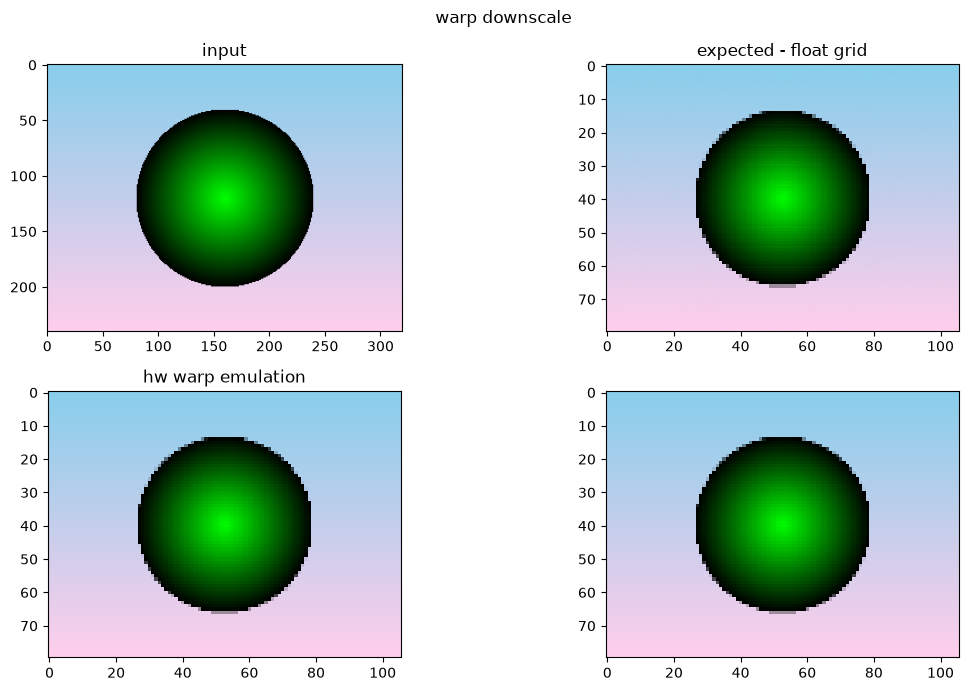

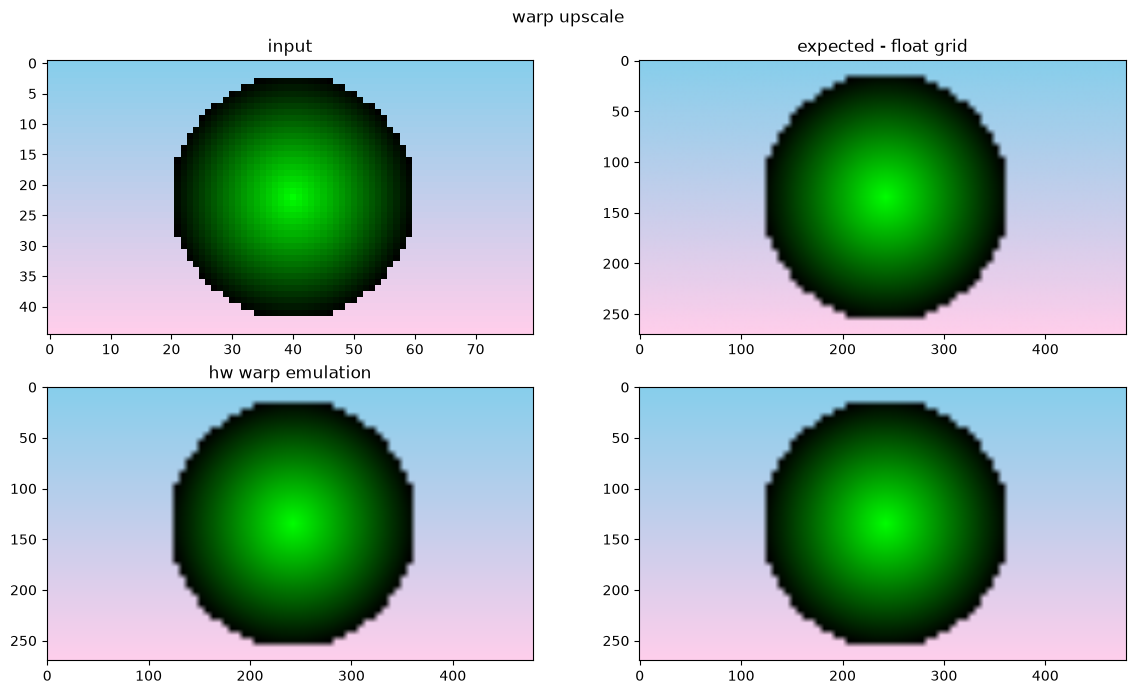

In [30]:
import matplotlib.pyplot as plt


def show_all(x, expected, q_res, hw_res, name):
    def to_img(t):
        if hasattr(t, 'detach'):                  # torch tensor -> numpy
            t = t.detach().cpu().numpy()
        return t.squeeze().transpose((1, 2, 0)).astype(np.uint8)

    fig, axs = plt.subplots(2, 2, figsize=(12, 7))
    axs[0, 0].imshow(to_img(x));        axs[0, 0].set_title('input')
    axs[0, 1].imshow(to_img(expected)); axs[0, 1].set_title('expected - float grid')
    axs[1, 0].imshow(to_img(q_res));    axs[1, 0].set_title('close to hw')
    axs[1, 1].imshow(to_img(hw_res));    axs[1, 0].set_title('hw warp emulation')
    fig.suptitle(f'warp {name}')
    plt.tight_layout()
    plt.show()


show_all(x_downscale, expected_downscale, q_res_downscale, npe_warp_emu_downscale, 'downscale')
show_all(x_upscale, expected_upscale, q_res_upscale, npe_warp_emu_upscale, 'upscale')